## 0. Setup

In [ ]:
import os, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_val_predict,
                                     cross_validate, learning_curve, validation_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             confusion_matrix, roc_curve, precision_recall_curve, silhouette_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
import joblib

warnings.filterwarnings("ignore")
RS = 42
np.random.seed(RS)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
MC = {"Logistic Regression": "#1f77b4", "PCA + Logistic Regression": "#17becf", "Decision Tree": "#ff7f0e",
      "Random Forest": "#2ca02c", "MLP": "#d62728", "Age-only baseline": "#7f7f7f"}
FACTS = {}

def savefig(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def save_table(df_, name):
    df_.to_csv(f"results/{name}.csv")

DATA_PATH = "healthcare-dataset-stroke-data.csv"

## 1. Problem definition and data audit  *(CO1)*

**Task type:** binary classification, `stroke ∈ {0,1}`.  
**Why it matters:** stroke is a leading cause of death and disability; screening resources are limited, so a model that *ranks* patients by risk and flags a manageable high-risk group is useful for preventive care.  
**Key challenge:** the positive class is rare (~5%), so plain accuracy is misleading (a model that always says "no stroke" scores ~95%).

In [ ]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
display(raw.head())
audit = pd.DataFrame({"dtype": raw.dtypes.astype(str), "missing": raw.isna().sum(),
                      "missing_%": (raw.isna().mean() * 100).round(2), "unique": raw.nunique()})
display(audit)
print("Duplicate patient ids:", raw.id.duplicated().sum())
print("Stroke prevalence: %.2f%%  (%d of %d)" % (raw.stroke.mean() * 100, raw.stroke.sum(), len(raw)))
print("Gender 'Other' rows:", (raw.gender == "Other").sum())
print("Max age with work_type='children':", raw.loc[raw.work_type == "children", "age"].max())
print("BMI missing: %d rows, stroke rate among them = %.1f%% (vs %.1f%% overall)" %
      (raw.bmi.isna().sum(), raw.loc[raw.bmi.isna(), "stroke"].mean() * 100, raw.stroke.mean() * 100))
print("Smoking status 'Unknown': %.1f%% of rows" % ((raw.smoking_status == "Unknown").mean() * 100))

Shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


,dtype,missing,missing_%,unique
id,int64,0,0.00,5110
gender,object,0,0.00,3
age,float64,0,0.00,104
hypertension,int64,0,0.00,2
heart_disease,int64,0,0.00,2
ever_married,object,0,0.00,2
work_type,object,0,0.00,5
Residence_type,object,0,0.00,2
avg_glucose_level,float64,0,0.00,3979
bmi,float64,201,3.93,418


Duplicate patient ids: 0
Stroke prevalence: 4.87%  (249 of 5110)
Gender 'Other' rows: 1
Max age with work_type='children': 16.0
BMI missing: 201 rows, stroke rate among them = 19.9% (vs 4.9% overall)
Smoking status 'Unknown': 30.2% of rows


**Audit findings that drive the preprocessing decisions**
* `bmi` has 201 missing values – and **those patients have a much higher stroke rate (~20%)**, so missingness itself is informative. We impute with the median *and* add a missing-indicator feature.
* `gender = Other` occurs once – it cannot be learned from or validated, so that row is removed.
* `smoking_status = Unknown` is ~30% of rows and is largely children (smoking status not recorded). It is kept as its own category rather than being guessed.
* `id` is an identifier with no predictive meaning and is dropped.
* The target is heavily imbalanced (~5% positive).

In [ ]:
df = raw.drop(columns="id")
df = df[df.gender != "Other"].reset_index(drop=True)
num_cols = ["age", "avg_glucose_level", "bmi"]
bin_cols = ["hypertension", "heart_disease"]
cat_cols = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
ALL = num_cols + bin_cols + cat_cols
TOP4 = ["age", "heart_disease", "avg_glucose_level", "hypertension"]   # the paper's "optimal" features
FACTS.update(n_raw=len(raw), n_clean=len(df), n_pos=int(df.stroke.sum()), prevalence=float(df.stroke.mean()),
             bmi_missing=int(raw.bmi.isna().sum()), bmi_missing_stroke_rate=float(raw.loc[raw.bmi.isna(), "stroke"].mean()))
print(df.shape)

(5109, 11)


## 2. Exploratory data analysis  *(CO1)*

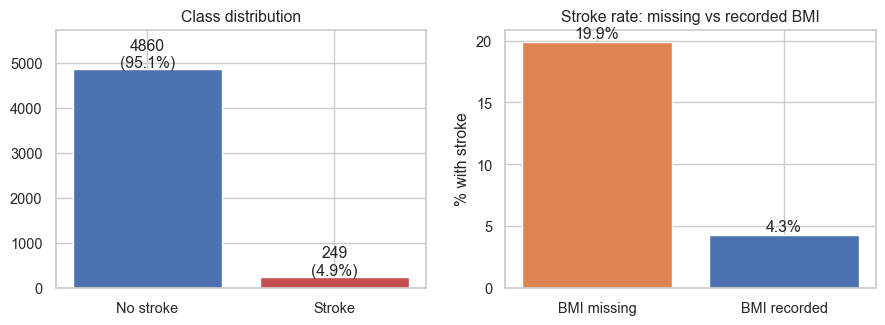

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
vc = df.stroke.value_counts().sort_index()
ax[0].bar(["No stroke", "Stroke"], vc.values, color=["#4c72b0", "#c44e52"])
for i, v in enumerate(vc.values):
    ax[0].text(i, v + 40, f"{v}\n({v / len(df) * 100:.1f}%)", ha="center")
ax[0].set_title("Class distribution"); ax[0].set_ylim(0, vc.max() * 1.18)
bmi_grp = np.where(df.bmi.isna(), "BMI missing", "BMI recorded")
r = df.groupby(bmi_grp).stroke.mean() * 100
ax[1].bar(r.index, r.values, color=["#dd8452", "#4c72b0"])
for i, v in enumerate(r.values):
    ax[1].text(i, v + 0.3, f"{v:.1f}%", ha="center")
ax[1].set_title("Stroke rate: missing vs recorded BMI"); ax[1].set_ylabel("% with stroke")
savefig("fig01_target_and_missing")

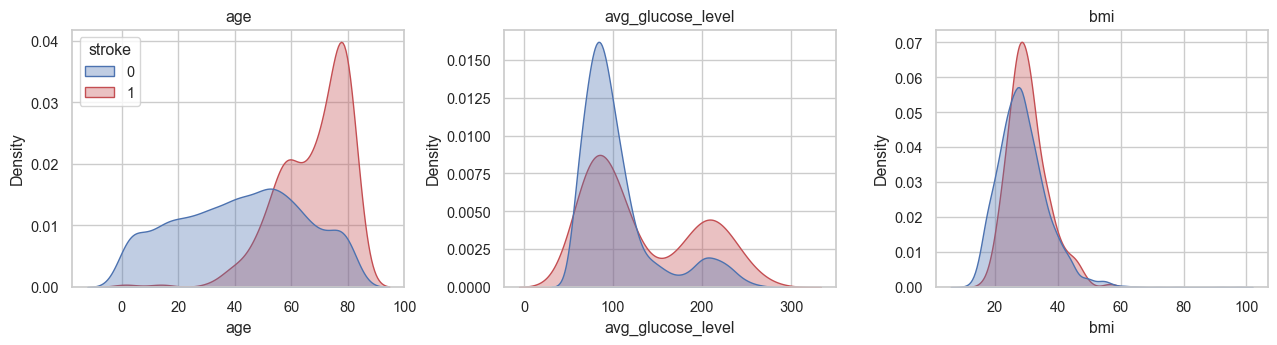

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, c in zip(ax, num_cols):
    sns.kdeplot(data=df, x=c, hue="stroke", common_norm=False, fill=True, alpha=.35, ax=a,
                palette={0: "#4c72b0", 1: "#c44e52"}, legend=(c == "age"))
    a.set_title(c)
savefig("fig02_numeric_distributions")

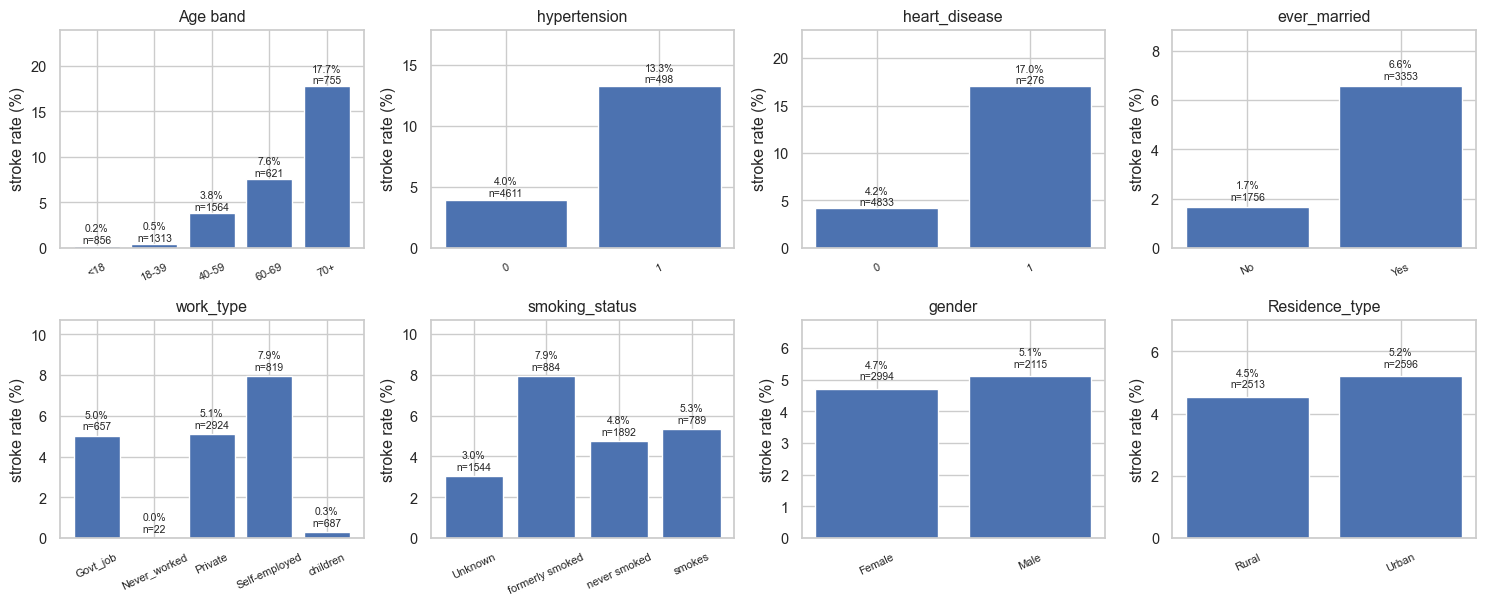

In [ ]:
bands = pd.cut(df.age, [0, 18, 40, 60, 70, 100], right=False, labels=["<18", "18-39", "40-59", "60-69", "70+"])
panels = {"Age band": bands, "hypertension": df.hypertension, "heart_disease": df.heart_disease,
          "ever_married": df.ever_married, "work_type": df.work_type, "smoking_status": df.smoking_status,
          "gender": df.gender, "Residence_type": df.Residence_type}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for a, (title, col) in zip(axes.ravel(), panels.items()):
    g = df.groupby(col).stroke.agg(["mean", "count"])
    a.bar(g.index.astype(str), g["mean"] * 100, color="#4c72b0")
    for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
        a.text(i, m * 100 + 0.3, f"{m * 100:.1f}%\nn={n}", ha="center", fontsize=7.5)
    a.set_title(title); a.set_ylim(0, g["mean"].max() * 100 * 1.35)
    a.tick_params(axis="x", rotation=25, labelsize=8)
    a.set_ylabel("stroke rate (%)")
savefig("fig03_stroke_rate_by_group")

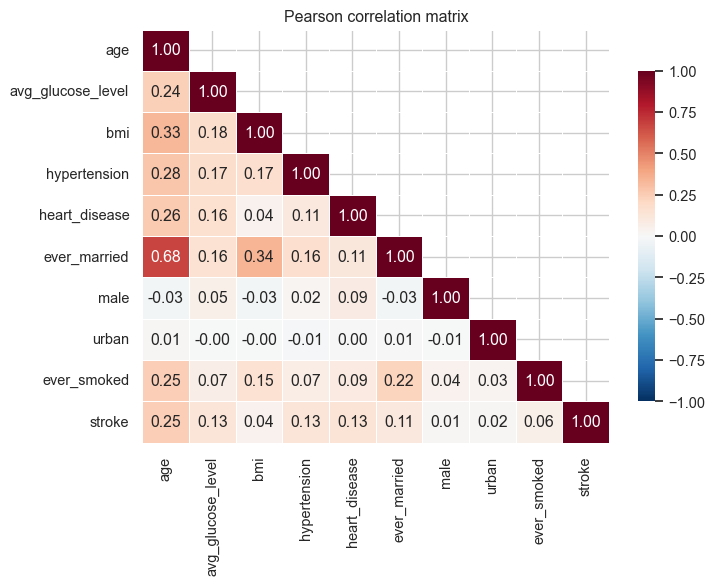

Correlation of each feature with stroke:
 age                  0.245
heart_disease        0.135
avg_glucose_level    0.132
hypertension         0.128
ever_married         0.108
ever_smoked          0.059
bmi                  0.042
urban                0.015
male                 0.009
Name: stroke, dtype: float64


In [ ]:
enc = df.copy()
enc["ever_married"] = (enc.ever_married == "Yes").astype(int)
enc["male"] = (enc.gender == "Male").astype(int)
enc["urban"] = (enc.Residence_type == "Urban").astype(int)
enc["ever_smoked"] = enc.smoking_status.isin(["formerly smoked", "smokes"]).astype(int)
corr = enc[["age", "avg_glucose_level", "bmi", "hypertension", "heart_disease", "ever_married", "male", "urban",
            "ever_smoked", "stroke"]].corr()
plt.figure(figsize=(7.5, 6))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), 1), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Pearson correlation matrix")
savefig("fig04_correlation")
print("Correlation of each feature with stroke:\n", corr["stroke"].drop("stroke").sort_values(ascending=False).round(3))

### Statistical tests – which attributes differ between stroke and non-stroke patients?
* Numeric: Mann–Whitney U (effect size = probability that a random stroke patient has the larger value; 0.5 = no effect).
* Categorical/binary: χ² test (effect size = Cramér's V).

In [ ]:
rows = []
for c in num_cols:
    a_ = df.loc[df.stroke == 1, c].dropna(); b_ = df.loc[df.stroke == 0, c].dropna()
    u, p = stats.mannwhitneyu(a_, b_)
    rows.append([c, "Mann-Whitney U", f"median {a_.median():.1f} vs {b_.median():.1f}", u / (len(a_) * len(b_)), p])
for c in bin_cols + cat_cols:
    ct = pd.crosstab(df[c], df.stroke)
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rows.append([c, "Chi-square", "-", v, p])
tests = pd.DataFrame(rows, columns=["feature", "test", "summary (stroke vs no stroke)", "effect size", "p-value"]).set_index("feature")
tests["significant (p<0.05)"] = tests["p-value"] < 0.05
display(tests.round(4))
save_table(tests, "stat_tests")

,test,summary (stroke vs no stroke),effect size,p-value,significant (p<0.05)
feature,,,,,
age,Mann-Whitney U,median 71.0 vs 43.0,0.8345,0.0000,True
avg_glucose_level,Mann-Whitney U,median 105.2 vs 91.5,0.6107,0.0000,True
bmi,Mann-Whitney U,median 29.7 vs 28.0,0.5792,0.0001,True
hypertension,Chi-square,-,0.1264,0.0000,True
heart_disease,Chi-square,-,0.1329,0.0000,True
gender,Chi-square,-,0.0082,0.5598,False
ever_married,Chi-square,-,0.1073,0.0000,True
work_type,Chi-square,-,0.0981,0.0000,True
Residence_type,Chi-square,-,0.0145,0.2998,False


**EDA take-aways**
1. **Age is by far the strongest signal**; stroke rate climbs steeply after 60.
2. Hypertension, heart disease and high glucose all raise the rate, and are only weakly correlated with each other – each carries independent information.
3. `ever_married` and `work_type` look "significant" but are mostly **proxies for age** (children are unmarried and not working). We will test this properly with a multivariable model in Section 8.
4. Residence type and gender carry almost no signal.

## 3. Train / test split and preprocessing pipeline  *(CO1)*
**Split first (80/20, stratified)**; the 20% test set is touched only once, for final evaluation.  
All preprocessing (median imputation + missing indicator, scaling, one-hot encoding) is inside the model `Pipeline`, so in cross-validation it is re-fitted on each training fold – **no leakage**.

In [ ]:
X = df.drop(columns="stroke"); y = df.stroke
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print(f"Train: {X_train.shape}, stroke={y_train.sum()} ({y_train.mean() * 100:.2f}%)")
print(f"Test : {X_test.shape}, stroke={y_test.sum()} ({y_test.mean() * 100:.2f}%)")
FACTS.update(n_train=len(X_train), n_test=len(X_test), pos_train=int(y_train.sum()), pos_test=int(y_test.sum()))

def make_prep(num=num_cols, binary=bin_cols, cat=cat_cols, ind=True):
    tr = []
    if num:
        tr.append(("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=ind)),
                                    ("sc", StandardScaler())]), num))
    if binary:
        tr.append(("bin", "passthrough", binary))
    if cat:
        tr.append(("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat))
    return ColumnTransformer(tr, verbose_feature_names_out=False)

prep_eda = make_prep().fit(X_train)
Z_train = prep_eda.transform(X_train); Z_test = prep_eda.transform(X_test)
feat_names = list(prep_eda.get_feature_names_out())
print(len(feat_names), "model features:", feat_names)

Train: (4087, 10), stroke=199 (4.87%)
Test : (1022, 10), stroke=50 (4.89%)
18 model features: ['age', 'avg_glucose_level', 'bmi', 'missingindicator_bmi', 'hypertension', 'heart_disease', 'gender_Male', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


## 4. Unsupervised analysis: PCA and K-Means  *(CO4, CO5)*
Fitted on the **training set only**. Purpose: (i) understand the structure of the feature space, (ii) test whether stroke cases form clusters (the paper concluded they do not), (iii) decide whether dimensionality reduction helps prediction (used later in the *PCA + Logistic Regression* model).

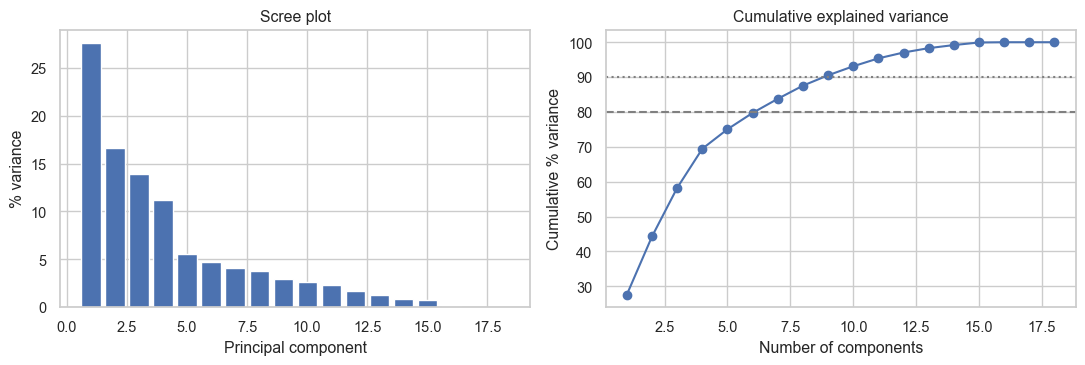

7 components explain >=80% of variance, 9 explain >=90%. PC1+PC2 = 44.3%


In [ ]:
pca = PCA(random_state=RS).fit(Z_train)
ev = pca.explained_variance_ratio_; cum = np.cumsum(ev)
k80 = int(np.argmax(cum >= .80) + 1); k90 = int(np.argmax(cum >= .90) + 1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(1, len(ev) + 1), ev * 100, color="#4c72b0"); ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("% variance")
ax[0].set_title("Scree plot")
ax[1].plot(range(1, len(ev) + 1), cum * 100, marker="o"); ax[1].axhline(80, ls="--", c="grey"); ax[1].axhline(90, ls=":", c="grey")
ax[1].set_xlabel("Number of components"); ax[1].set_ylabel("Cumulative % variance"); ax[1].set_title("Cumulative explained variance")
savefig("fig05_pca_scree")
print(f"{k80} components explain >=80% of variance, {k90} explain >=90%. PC1+PC2 = {cum[1] * 100:.1f}%")
FACTS.update(pca_k80=k80, pca_k90=k90, pca_pc12=float(cum[1]))

Univariate ROC-AUC of each PC for stroke: {'PC1': 0.796, 'PC2': 0.606, 'PC3': 0.533, 'PC4': 0.631, 'PC5': 0.537, 'PC6': 0.526}


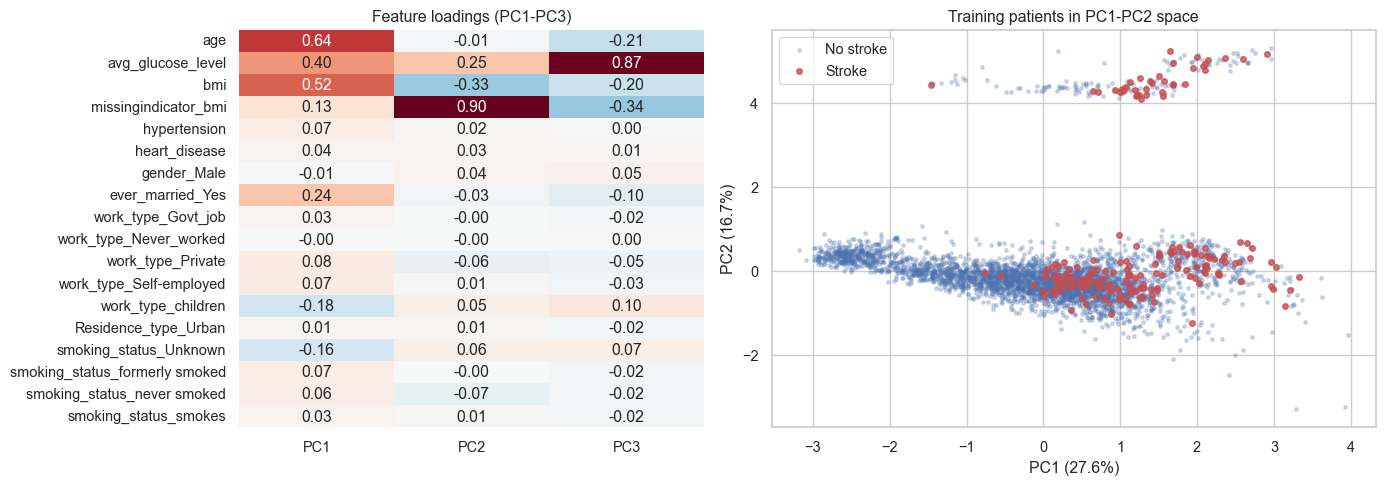

In [ ]:
load = pd.DataFrame(pca.components_[:3].T, index=feat_names, columns=["PC1", "PC2", "PC3"])
Zp = pca.transform(Z_train)
pc_auc = {f"PC{i + 1}": max(roc_auc_score(y_train, Zp[:, i]), 1 - roc_auc_score(y_train, Zp[:, i])) for i in range(6)}
print("Univariate ROC-AUC of each PC for stroke:", {k: round(v, 3) for k, v in pc_auc.items()})
FACTS["pc_auc"] = {k: float(v) for k, v in pc_auc.items()}
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})
sns.heatmap(load, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0], cbar=False)
ax[0].set_title("Feature loadings (PC1-PC3)")
neg = y_train.values == 0
ax[1].scatter(Zp[neg, 0], Zp[neg, 1], s=6, alpha=.25, c="#4c72b0", label="No stroke")
ax[1].scatter(Zp[~neg, 0], Zp[~neg, 1], s=16, alpha=.8, c="#c44e52", label="Stroke")
ax[1].set_xlabel(f"PC1 ({ev[0] * 100:.1f}%)"); ax[1].set_ylabel(f"PC2 ({ev[1] * 100:.1f}%)"); ax[1].legend()
ax[1].set_title("Training patients in PC1-PC2 space")
savefig("fig06_pca_loadings_scatter")

### K-Means clustering – risk segments

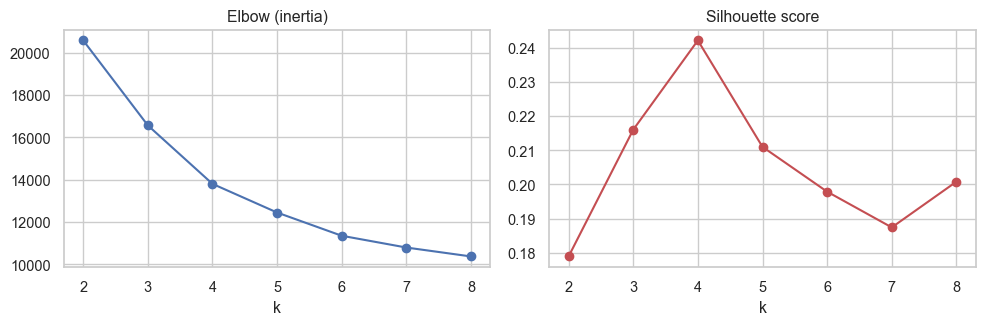

{2: 0.179, 3: 0.216, 4: 0.242, 5: 0.211, 6: 0.198, 7: 0.187, 8: 0.201}


In [ ]:
Ks = range(2, 9); inertia, sil = [], []
for k in Ks:
    km = KMeans(k, n_init=10, random_state=RS).fit(Z_train)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z_train, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(list(Ks), inertia, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(list(Ks), sil, marker="o", c="#c44e52"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
savefig("fig07_kmeans_selection")
print(dict(zip(Ks, np.round(sil, 3))))

In [ ]:
K_FINAL = 4
km = KMeans(K_FINAL, n_init=20, random_state=RS).fit(Z_train)
tr_lab = km.labels_; te_lab = km.predict(Z_test)
prof = X_train.assign(cluster=tr_lab, stroke=y_train.values).groupby("cluster").agg(
    n=("age", "size"), mean_age=("age", "mean"), mean_glucose=("avg_glucose_level", "mean"), mean_bmi=("bmi", "mean"),
    pct_hypertension=("hypertension", lambda s: s.mean() * 100), pct_heart_disease=("heart_disease", lambda s: s.mean() * 100),
    pct_married=("ever_married", lambda s: (s == "Yes").mean() * 100), stroke_rate_train=("stroke", lambda s: s.mean() * 100))
prof["stroke_rate_test"] = X_test.assign(cluster=te_lab, stroke=y_test.values).groupby("cluster").stroke.mean() * 100
prof["pct_of_patients"] = prof.n / prof.n.sum() * 100
prof["pct_of_all_strokes"] = pd.Series(y_train.values).groupby(tr_lab).sum() / y_train.sum() * 100
prof["main_work_type"] = X_train.assign(cluster=tr_lab).groupby("cluster").work_type.agg(lambda s: s.value_counts().index[0])
display(prof.round(1))
save_table(prof.round(2), "kmeans_profiles")
FACTS.update(kmeans_k=K_FINAL, kmeans_sil=float(sil[K_FINAL - 2]))

,n,mean_age,mean_glucose,mean_bmi,pct_hypertension,pct_heart_disease,pct_married,stroke_rate_train,stroke_rate_test,pct_of_patients,pct_of_all_strokes,main_work_type
cluster,,,,,,,,,,,,
0,504,60.2,203.4,33.3,25.6,15.3,90.5,12.3,12.4,12.3,31.2,Private
1,1107,15.1,93.5,22.3,0.1,0.1,8.1,0.1,0.4,27.1,0.5,children
2,2313,52.3,89.4,31.1,9.6,5.4,87.5,4.3,5.0,56.6,49.7,Private
3,163,53.6,122.5,NaN,21.5,18.4,78.5,22.7,7.9,4.0,18.6,Private


**Reading the clusters (k = 4; silhouette ≈ 0.24, i.e. weak separation).**
* **Cluster 0 – older, high-glucose, comorbid (≈12% of patients):** mean age ≈ 60, mean glucose ≈ 203 mg/dL, 26% hypertensive, 15% with heart disease. Stroke rate ≈ 12% in both train and test (≈ 2.5× the population rate) – this segment alone holds ≈ 31% of all strokes.
* **Cluster 1 – children / young people (≈27%):** mean age ≈ 15, almost no strokes (0.1% train, 0.4% test).
* **Cluster 2 – middle-aged, normal glucose (≈57%):** stroke rate ≈ 4–5%, close to the population rate, but because it is large it contains ≈ 50% of all strokes.
* **Cluster 3 – BMI not recorded (≈4%):** K-Means isolates the missing-BMI group because of the missing-indicator feature. Its stroke rate is high in training (≈ 23%) but much lower in the small test slice (≈ 8%), so this is noisy – see the caveat in Section 9c.

Clustering is therefore useful as *descriptive risk segmentation*, but stroke patients are **not isolated in a cluster of their own** (weak silhouette; half of all strokes sit in the large middle-aged cluster). This agrees with the paper's PCA observation: **unsupervised structure alone cannot detect stroke – a supervised model is needed.**

**PCA findings.** PC1 (≈ 28% of variance) is essentially an *"age / body-size / glucose" axis* (loadings: age 0.64, BMI 0.52, glucose 0.40, marital status 0.24) and on its own reaches ROC-AUC ≈ 0.80 for stroke – close to age by itself (0.83). Seven components are needed for 80% of the variance and the first two cover only ≈ 44%, so, like the paper, we find **no strong low-dimensional compression**; PCA is therefore tested as a pre-processing step inside a model (PCA + Logistic Regression) rather than assumed to help.

## 5. Models, hyper-parameter tuning and cross-validation  *(CO2, CO3, CO5, CO6)*

| # | Model | Why it is included | Imbalance handling |
|---|---|---|---|
| 1 | Logistic Regression | Interpretable baseline; probabilistic output (log-loss) | `class_weight="balanced"` |
| 2 | PCA + Logistic Regression | Tests whether dimensionality reduction helps (Unit V) | `class_weight="balanced"` |
| 3 | Decision Tree | Human-readable rules (Unit III) | `class_weight="balanced"`, pruned |
| 4 | Random Forest | Bagging ensemble, reduces variance (Unit VI) | `class_weight="balanced_subsample"` |
| 5 | MLP (feed-forward NN) | Non-linear model (Unit V) | random over-sampling *inside* the CV pipeline |

**Tuning:** stratified 5-fold CV on the training set only; refit criterion = **PR-AUC** (average precision), the metric most sensitive to performance on the rare class; ROC-AUC is also recorded.

In [ ]:
LR = lambda: LogisticRegression(class_weight="balanced", max_iter=5000, random_state=RS)
specs = {
    "Logistic Regression": dict(
        est=Pipeline([("prep", make_prep()), ("clf", LR())]),
        grid={"clf__C": [0.001, 0.01, 0.1, 1, 10, 100]}, kind="grid"),
    "PCA + Logistic Regression": dict(
        est=Pipeline([("prep", make_prep()), ("pca", PCA(random_state=RS)), ("clf", LR())]),
        grid={"pca__n_components": [2, 4, 6, 8, 10, 12, 14, 18], "clf__C": [0.01, 0.1, 1, 10]}, kind="grid"),
    "Decision Tree": dict(
        est=Pipeline([("prep", make_prep()), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RS))]),
        grid={"clf__max_depth": [2, 3, 4, 5, 6, 8], "clf__min_samples_leaf": [5, 10, 20, 40, 80],
              "clf__ccp_alpha": [0, 0.0005, 0.002, 0.005]}, kind="grid"),
    "Random Forest": dict(
        est=Pipeline([("prep", make_prep()), ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                                             random_state=RS, n_jobs=-1))]),
        grid={"clf__max_depth": [3, 4, 6, 8, 12, None], "clf__min_samples_leaf": [3, 5, 10, 20, 40],
              "clf__max_features": ["sqrt", 0.5]}, kind="random", n_iter=14),
    "MLP": dict(
        est=ImbPipeline([("prep", make_prep()), ("ros", RandomOverSampler(random_state=RS)),
                         ("clf", MLPClassifier(max_iter=250, random_state=RS))]),
        grid={"ros__sampling_strategy": [0.25, 0.5, 1.0], "clf__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)],
              "clf__alpha": [1e-3, 1e-2, 1e-1, 1, 3], "clf__learning_rate_init": [1e-3, 3e-3]}, kind="random", n_iter=12),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RS)
scoring = {"ap": "average_precision", "auc": "roc_auc"}
fitted, search_rows = {}, []
for name, sp in specs.items():
    t0 = time.time()
    if sp["kind"] == "grid":
        s = GridSearchCV(sp["est"], sp["grid"], scoring=scoring, refit="ap", cv=cv, n_jobs=1)
    else:
        s = RandomizedSearchCV(sp["est"], sp["grid"], n_iter=sp["n_iter"], scoring=scoring, refit="ap", cv=cv,
                               random_state=RS, n_jobs=1)
    s.fit(X_train, y_train)
    fitted[name] = s.best_estimator_
    i = s.best_index_
    search_rows.append([name, str({k.split("__")[-1]: v for k, v in s.best_params_.items()}),
                        s.cv_results_["mean_test_ap"][i], s.cv_results_["mean_test_auc"][i], round(time.time() - t0, 1)])
    print(f"{name:28s} CV PR-AUC={s.cv_results_['mean_test_ap'][i]:.3f}  CV ROC-AUC={s.cv_results_['mean_test_auc'][i]:.3f}  "
          f"best={s.best_params_}  ({time.time() - t0:.0f}s)")
search_df = pd.DataFrame(search_rows, columns=["Model", "Best hyper-parameters", "CV PR-AUC", "CV ROC-AUC", "Tuning time (s)"]).set_index("Model")
display(search_df.round(3)); save_table(search_df.round(4), "tuning_results")

# Reference model: age alone (is the extra complexity worth it?)
base_age = Pipeline([("prep", make_prep(num=["age"], binary=[], cat=[])), ("clf", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
all_models = {**fitted, "Age-only baseline": base_age}

Logistic Regression          CV PR-AUC=0.228  CV ROC-AUC=0.854  best={'clf__C': 0.01}  (1s)
PCA + Logistic Regression    CV PR-AUC=0.230  CV ROC-AUC=0.849  best={'clf__C': 1, 'pca__n_components': 6}  (8s)
Decision Tree                CV PR-AUC=0.193  CV ROC-AUC=0.795  best={'clf__ccp_alpha': 0, 'clf__max_depth': 6, 'clf__min_samples_leaf': 10}  (44s)
Random Forest                CV PR-AUC=0.226  CV ROC-AUC=0.846  best={'clf__min_samples_leaf': 10, 'clf__max_features': 0.5, 'clf__max_depth': None}  (117s)


**Reading the tuning results.** Strong regularisation wins (`C = 0.01`, MLP `alpha = 1`, tree depth 6 with ≥ 10 samples per leaf, RF leaves ≥ 10): with only ~200 stroke cases the data cannot support complex models, so the tuner repeatedly chooses *simpler / smoother* ones. The MLP has the best CV PR-AUC (0.248), but every model except the decision tree lies within about 0.02 of the others, which is well inside the fold-to-fold noise (see Section 7). PCA + Logistic Regression keeps 6 of 18 encoded features' worth of components with no loss in performance.

## 6. Evaluation on the untouched test set  *(CO3, CO6)*

Because accuracy is misleading at 5% prevalence, we evaluate three ways:
1. **Threshold-free** ranking quality: ROC-AUC, PR-AUC (random-guess PR-AUC = prevalence ≈ 0.05), Log-Loss, Brier score.
2. **Default threshold 0.5**.
3. **Screening threshold** – the highest threshold that still catches ≥ 80% of strokes *in out-of-fold training predictions* (chosen without ever looking at the test set). This mirrors real use: a clinic first decides how many strokes it must not miss.

In [ ]:
def metrics_at(y_, p_, thr):
    yh = (p_ >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, yh, labels=[0, 1]).ravel()
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn); spec = tn / (tn + fp)
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    f2 = 5 * prec * rec / (4 * prec + rec) if 4 * prec + rec else 0.0
    return dict(Accuracy=(tp + tn) / len(y_), Precision=prec, Recall=rec, Specificity=spec, F1=f1, F2=f2,
                Flagged_pct=(tp + fp) / len(y_) * 100, Lift=(prec / y_.mean() if prec else 0.0), TN=tn, FP=fp, FN=fn, TP=tp)

def screening_threshold(y_, p_, target=0.80):
    yv = np.asarray(y_); npos = yv.sum()
    for t in np.sort(np.unique(p_))[::-1]:
        if ((p_ >= t) & (yv == 1)).sum() / npos >= target:
            return float(t)
    return float(p_.min())

P_oof, P_test, THR = {}, {}, {}
for n, m in all_models.items():
    P_oof[n] = cross_val_predict(clone(m), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    P_test[n] = m.predict_proba(X_test)[:, 1]
    THR[n] = screening_threshold(y_train, P_oof[n], 0.80)

# Calibrated probabilities (sigmoid / Platt) so log-loss and Brier are meaningful for class-weighted models
P_cal = {}
for n, m in all_models.items():
    if n == "Age-only baseline":
        P_cal[n] = P_test[n]
    else:
        P_cal[n] = CalibratedClassifierCV(clone(m), method="sigmoid", cv=5).fit(X_train, y_train).predict_proba(X_test)[:, 1]

yt = y_test.values
rows = []
for n in all_models:
    rows.append(dict(Model=n, ROC_AUC=roc_auc_score(yt, P_test[n]), PR_AUC=average_precision_score(yt, P_test[n]),
                     LogLoss_raw=log_loss(yt, np.clip(P_test[n], 1e-6, 1 - 1e-6)),
                     LogLoss_calibrated=log_loss(yt, np.clip(P_cal[n], 1e-6, 1 - 1e-6)),
                     Brier_calibrated=brier_score_loss(yt, P_cal[n])))
tab_rank = pd.DataFrame(rows).set_index("Model")
print(f"Reference: PR-AUC of a random model = prevalence = {yt.mean():.3f};  LogLoss of always predicting prevalence = "
      f"{log_loss(yt, np.full(len(yt), y_train.mean())):.3f}")
display(tab_rank.round(3)); save_table(tab_rank.round(4), "test_ranking_metrics")

tab_05 = pd.DataFrame({n: metrics_at(yt, P_test[n], 0.5) for n in all_models}).T
tab_scr = pd.DataFrame({n: {"Threshold": THR[n], **metrics_at(yt, P_test[n], THR[n])} for n in all_models}).T
print("\n--- Default threshold 0.5 ---"); display(tab_05.round(3)); save_table(tab_05.round(4), "test_threshold_0.5")
print("\n--- Screening threshold (target recall 80% on out-of-fold training data) ---"); display(tab_scr.round(3)); save_table(tab_scr.round(4), "test_screening_threshold")

Reference: PR-AUC of a random model = prevalence = 0.049;  LogLoss of always predicting prevalence = 0.195


,ROC_AUC,PR_AUC,LogLoss_raw,LogLoss_calibrated,Brier_calibrated
Model,,,,,
Logistic Regression,0.835,0.209,0.491,0.159,0.042
PCA + Logistic Regression,0.836,0.204,0.489,0.159,0.042
Decision Tree,0.785,0.170,0.563,0.168,0.043
Random Forest,0.820,0.238,0.266,0.159,0.042
MLP,0.840,0.231,0.317,0.156,0.041
Age-only baseline,0.835,0.209,0.157,0.157,0.042



--- Default threshold 0.5 ---


,Accuracy,Precision,Recall,Specificity,F1,F2,Flagged_pct,Lift,TN,FP,FN,TP
Logistic Regression,0.751,0.143,0.82,0.748,0.244,0.422,27.984,2.930,727.0,245.0,9.0,41.0
PCA + Logistic Regression,0.746,0.138,0.80,0.743,0.235,0.408,28.376,2.819,722.0,250.0,10.0,40.0
Decision Tree,0.758,0.139,0.76,0.758,0.235,0.402,26.712,2.845,737.0,235.0,12.0,38.0
Random Forest,0.898,0.235,0.48,0.920,0.316,0.397,9.980,4.809,894.0,78.0,26.0,24.0
MLP,0.836,0.196,0.76,0.840,0.311,0.482,18.982,4.004,816.0,156.0,12.0,38.0
Age-only baseline,0.951,0.000,0.00,1.000,0.000,0.000,0.000,0.000,972.0,0.0,50.0,0.0



--- Screening threshold (target recall 80% on out-of-fold training data) ---


,Threshold,Accuracy,Precision,Recall,Specificity,F1,F2,Flagged_pct,Lift,TN,FP,FN,TP
Logistic Regression,0.497,0.748,0.141,0.82,0.744,0.241,0.418,28.376,2.890,723.0,249.0,9.0,41.0
PCA + Logistic Regression,0.472,0.722,0.130,0.82,0.717,0.224,0.397,30.920,2.652,697.0,275.0,9.0,41.0
Decision Tree,0.340,0.584,0.090,0.82,0.572,0.162,0.312,44.716,1.834,556.0,416.0,9.0,41.0
Random Forest,0.258,0.743,0.129,0.74,0.743,0.220,0.380,28.082,2.635,722.0,250.0,13.0,37.0
MLP,0.323,0.729,0.133,0.82,0.724,0.228,0.403,30.235,2.712,704.0,268.0,9.0,41.0
Age-only baseline,0.050,0.733,0.134,0.82,0.728,0.231,0.406,29.843,2.748,708.0,264.0,9.0,41.0


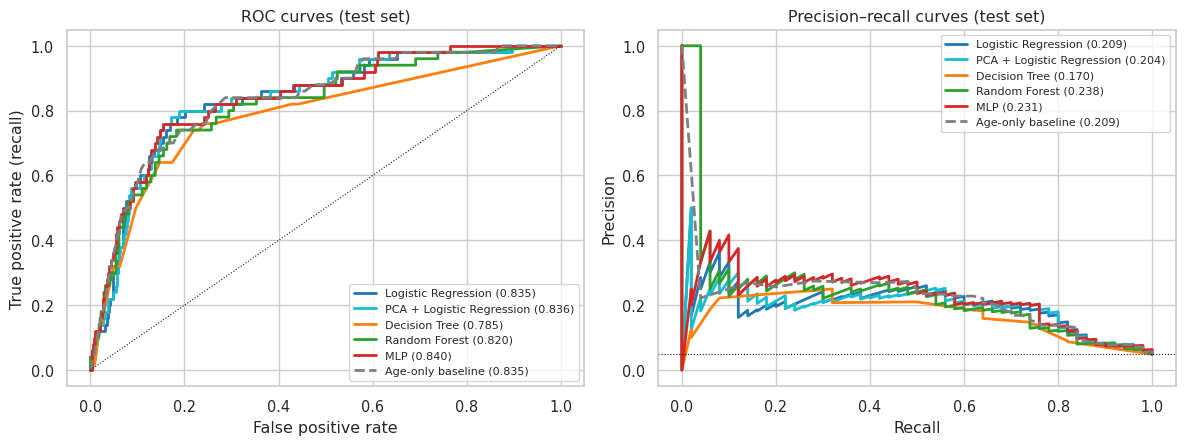

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for n in all_models:
    fpr, tpr, _ = roc_curve(yt, P_test[n]); ax[0].plot(fpr, tpr, c=MC[n], lw=2, ls="--" if "baseline" in n else "-",
                                                        label=f"{n} ({tab_rank.loc[n, 'ROC_AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(yt, P_test[n]); ax[1].plot(rc, pr, c=MC[n], lw=2, ls="--" if "baseline" in n else "-",
                                                                   label=f"{n} ({tab_rank.loc[n, 'PR_AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], c="k", lw=.8, ls=":"); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)")
ax[0].set_title("ROC curves (test set)"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].axhline(yt.mean(), c="k", lw=.8, ls=":"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision–recall curves (test set)"); ax[1].legend(fontsize=8)
savefig("fig08_roc_pr_curves")

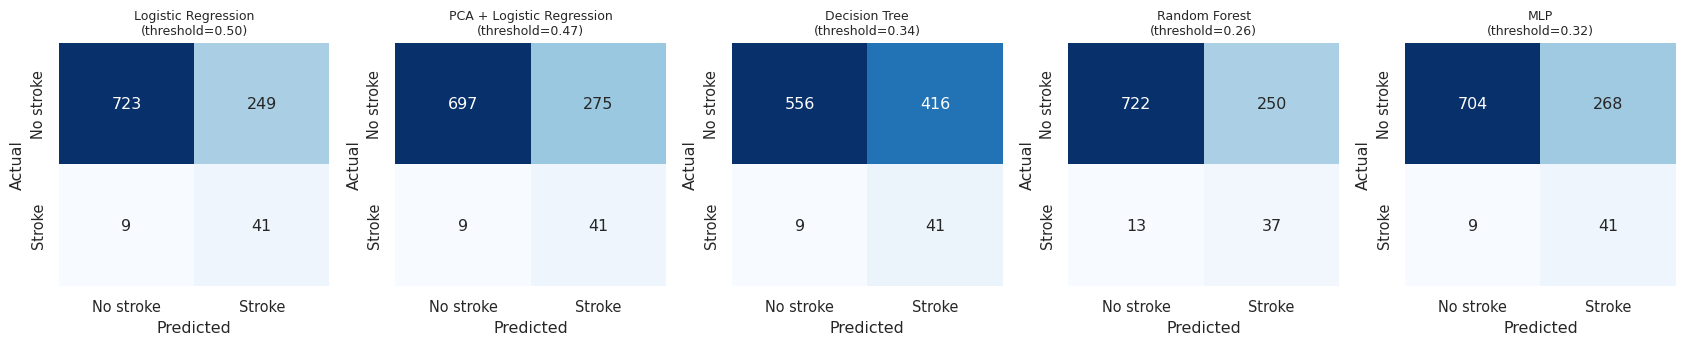

In [ ]:
five = list(fitted)
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for a, n in zip(axes, five):
    cm = confusion_matrix(yt, (P_test[n] >= THR[n]).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=["No stroke", "Stroke"],
                yticklabels=["No stroke", "Stroke"])
    a.set_title(f"{n}\n(threshold={THR[n]:.2f})", fontsize=9); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
savefig("fig09_confusion_matrices")

### Uncertainty: bootstrap 95% confidence intervals and paired comparisons
The test set has only ~50 strokes, so single numbers are noisy. We resample the test set 500 times (same resamples for every model, so comparisons are paired).

In [ ]:
B = 500; rng = np.random.default_rng(RS); idx_all = rng.integers(0, len(yt), (B, len(yt)))
boot = {n: {"auc": [], "ap": [], "rec": [], "prec": []} for n in all_models}
for idx in idx_all:
    if yt[idx].sum() == 0:
        continue
    for n in all_models:
        p_ = P_test[n][idx]; y_ = yt[idx]; yh = p_ >= THR[n]
        boot[n]["auc"].append(roc_auc_score(y_, p_)); boot[n]["ap"].append(average_precision_score(y_, p_))
        boot[n]["rec"].append((yh & (y_ == 1)).sum() / y_.sum()); boot[n]["prec"].append((yh & (y_ == 1)).sum() / max(yh.sum(), 1))
ci_rows = []
for n in all_models:
    f = lambda k: f"{np.mean(boot[n][k]):.3f} [{np.percentile(boot[n][k], 2.5):.3f}, {np.percentile(boot[n][k], 97.5):.3f}]"
    ci_rows.append([n, f("auc"), f("ap"), f("rec"), f("prec")])
ci_df = pd.DataFrame(ci_rows, columns=["Model", "ROC-AUC (95% CI)", "PR-AUC (95% CI)", "Recall @screen thr", "Precision @screen thr"]).set_index("Model")
display(ci_df); save_table(ci_df, "bootstrap_ci")

,ROC-AUC (95% CI),PR-AUC (95% CI),Recall @screen thr,Precision @screen thr
Model,,,,
Logistic Regression,"0.836 [0.786, 0.885]","0.223 [0.144, 0.319]","0.818 [0.710, 0.918]","0.141 [0.101, 0.182]"
PCA + Logistic Regression,"0.837 [0.788, 0.884]","0.217 [0.143, 0.309]","0.818 [0.710, 0.918]","0.129 [0.091, 0.168]"
Decision Tree,"0.785 [0.719, 0.844]","0.176 [0.116, 0.248]","0.819 [0.716, 0.916]","0.089 [0.064, 0.117]"
Random Forest,"0.821 [0.767, 0.873]","0.247 [0.153, 0.344]","0.741 [0.625, 0.854]","0.129 [0.092, 0.167]"
MLP,"0.840 [0.792, 0.890]","0.246 [0.162, 0.350]","0.818 [0.710, 0.918]","0.132 [0.094, 0.171]"
Age-only baseline,"0.835 [0.779, 0.888]","0.217 [0.147, 0.314]","0.819 [0.709, 0.913]","0.134 [0.098, 0.171]"


**Findings on the held-out test set (1,022 patients, 50 strokes)**
1. **Ranking quality:** ROC-AUC ≈ 0.82–0.84 for Logistic Regression, PCA + LR, Random Forest and MLP; the Decision Tree is clearly weaker (0.785). The bootstrap intervals (about ± 0.05) overlap heavily, so the four better models are **statistically indistinguishable** on this test set.
2. **Accuracy is a trap.** At the default 0.5 threshold, the age-only baseline reaches 95.1% accuracy by predicting "no stroke" for everyone (recall 0). Random Forest reaches 89.8% accuracy but finds only 48% of strokes. That is why the screening threshold, recall, PR-AUC and lift are reported.
3. **At the screening threshold** (chosen on training data to catch ≥ 80% of strokes), Logistic Regression, PCA + LR, MLP and the age-only baseline each catch 41 of 50 strokes (82%) while flagging ≈ 28–31% of the population – a **precision of 13–14%, a ≈ 2.7–2.9× lift** over random selection. The Decision Tree needs to flag 45% of the population for the same recall. Random Forest caught 37 of 50 (74%); its 95% interval (0.63–0.85) is compatible with the 80% target, so this is sampling noise rather than a failure.
4. **Calibration matters for log-loss.** Raw class-weighted probabilities badly over-state risk (log-loss 0.27–0.56, worse than the 0.157 of the age-only model). After Platt calibration all models fall to 0.156–0.168. The MLP is nominally best (0.156) but only marginally better than age alone (0.157).
5. **An honest headline:** *age alone is a strong baseline* (test ROC-AUC 0.835). Multivariable models add real but small value – the clearest evidence is in repeated cross-validation (Section 7).

## 7. Stability: repeated cross-validation and model selection
5-fold CV repeated 3 times (15 folds) on the training data. The **standard deviation** across folds is an empirical measure of *variance*; the gap between training and validation score is a measure of *over-fitting*.

In [ ]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RS)
sc = {"auc": "roc_auc", "ap": "average_precision", "nll": "neg_log_loss"}
rep_rows = []
for n, m in all_models.items():
    r = cross_validate(clone(m), X_train, y_train, cv=rcv, scoring=sc, return_train_score=True, n_jobs=1)
    rep_rows.append(dict(Model=n, CV_ROC_AUC=r["test_auc"].mean(), CV_ROC_AUC_sd=r["test_auc"].std(),
                         CV_PR_AUC=r["test_ap"].mean(), CV_PR_AUC_sd=r["test_ap"].std(),
                         Train_ROC_AUC=r["train_auc"].mean(), Overfit_gap_AUC=r["train_auc"].mean() - r["test_auc"].mean()))
rep = pd.DataFrame(rep_rows).set_index("Model")
display(rep.round(3)); save_table(rep.round(4), "repeated_cv")
final_name = rep.loc[five, "CV_PR_AUC"].idxmax()
print(f"\nModel selected on TRAINING-data CV PR-AUC (never on the test set): {final_name}")
FACTS["final_name"] = final_name
final_model = fitted[final_name]

,CV_ROC_AUC,CV_ROC_AUC_sd,CV_PR_AUC,CV_PR_AUC_sd,Train_ROC_AUC,Overfit_gap_AUC
Model,,,,,,
Logistic Regression,0.853,0.020,0.231,0.034,0.862,0.008
PCA + Logistic Regression,0.850,0.023,0.231,0.032,0.854,0.004
Decision Tree,0.779,0.034,0.179,0.032,0.901,0.121
Random Forest,0.845,0.018,0.225,0.032,0.979,0.134
MLP,0.843,0.023,0.245,0.041,0.895,0.052
Age-only baseline,0.835,0.021,0.167,0.015,0.834,-0.000



Model selected on TRAINING-data CV PR-AUC (never on the test set): MLP


**Reading the repeated-CV table.** Logistic Regression (0.853 ± 0.020), PCA + LR (0.850), Random Forest (0.845) and MLP (0.843) are tied on ROC-AUC; the Decision Tree is lower and noisier (0.779 ± 0.034); the age-only baseline reaches 0.835. On PR-AUC the multivariable models (0.225–0.245) clearly beat age alone (0.167), i.e. the extra features help specifically in *ranking the rare positives near the top*. The pre-declared selection rule (highest mean CV PR-AUC among the five models) picks the **MLP**, but its lead over Logistic Regression (0.245 vs 0.231) is smaller than one fold-standard-deviation (≈ 0.04); the simpler, fully interpretable Logistic Regression is an equally defensible practical choice.

## 8. Bias–variance analysis  *(CO6)*
Three complementary views:
1. **Learning curves** – do models improve with more data (high variance) or plateau early (high bias)?
2. **Validation curve** for a decision tree – the textbook bias–variance trade-off as depth grows.
3. **Bootstrap decomposition** (Domingos 0-1 loss): train each model on 40 bootstrap resamples; *bias* = error of the majority ("main") prediction, *variance* = how often individual predictions disagree with it. This also shows why bagging (Random Forest) helps.

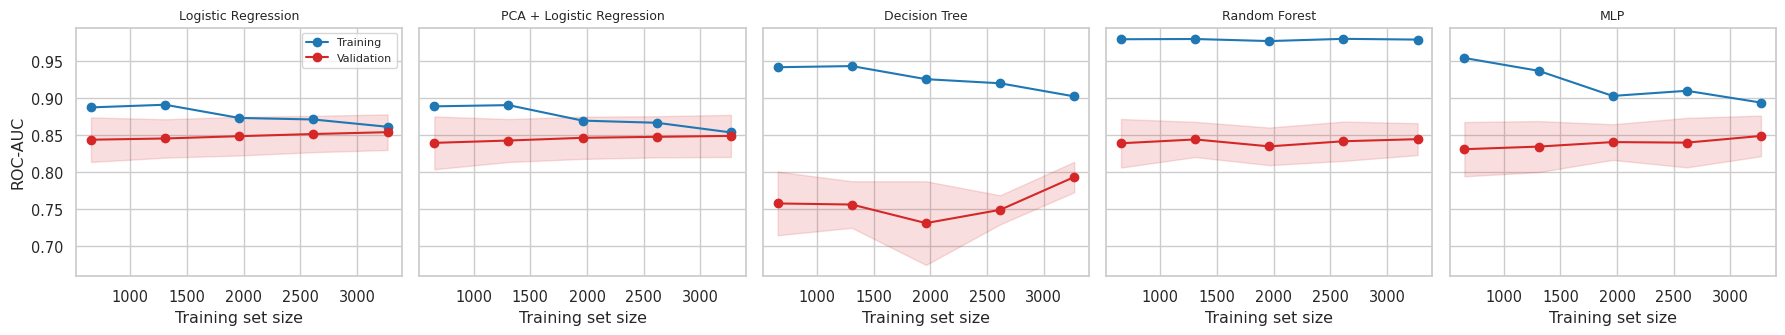

,Train AUC (full),Validation AUC (full),Gap
Model,,,
Logistic Regression,0.861,0.854,0.007
PCA + Logistic Regression,0.854,0.849,0.005
Decision Tree,0.903,0.793,0.109
Random Forest,0.980,0.845,0.135
MLP,0.894,0.849,0.045


In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5), sharey=True)
lc_rows = []
for a, n in zip(axes, five):
    ts, trs, vs = learning_curve(clone(fitted[n]), X_train, y_train, train_sizes=[.2, .4, .6, .8, 1.0], cv=cv,
                                 scoring="roc_auc", n_jobs=1, random_state=RS)
    a.plot(ts, trs.mean(1), "o-", c="#1f77b4", label="Training"); a.plot(ts, vs.mean(1), "o-", c="#d62728", label="Validation")
    a.fill_between(ts, vs.mean(1) - vs.std(1), vs.mean(1) + vs.std(1), color="#d62728", alpha=.15)
    a.set_title(n, fontsize=9); a.set_xlabel("Training set size")
    lc_rows.append([n, trs.mean(1)[-1], vs.mean(1)[-1], trs.mean(1)[-1] - vs.mean(1)[-1]])
axes[0].set_ylabel("ROC-AUC"); axes[0].legend(fontsize=8)
savefig("fig10_learning_curves")
lc_df = pd.DataFrame(lc_rows, columns=["Model", "Train AUC (full)", "Validation AUC (full)", "Gap"]).set_index("Model")
display(lc_df.round(3)); save_table(lc_df.round(4), "learning_curve_gaps")

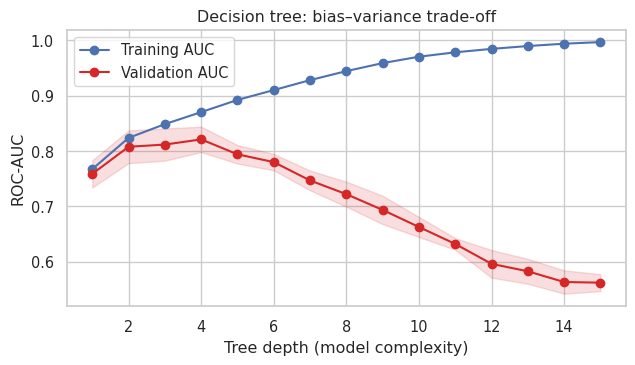

Best validation depth (unpruned leaves): 4


In [ ]:
depths = list(range(1, 16))
dt_base = Pipeline([("prep", make_prep()), ("clf", DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=1, random_state=RS))])
tr_s, va_s = validation_curve(dt_base, X_train, y_train, param_name="clf__max_depth", param_range=depths, cv=cv, scoring="roc_auc")
plt.figure(figsize=(6.5, 3.8))
plt.plot(depths, tr_s.mean(1), "o-", label="Training AUC"); plt.plot(depths, va_s.mean(1), "o-", c="#d62728", label="Validation AUC")
plt.fill_between(depths, va_s.mean(1) - va_s.std(1), va_s.mean(1) + va_s.std(1), color="#d62728", alpha=.15)
plt.xlabel("Tree depth (model complexity)"); plt.ylabel("ROC-AUC"); plt.legend(); plt.title("Decision tree: bias–variance trade-off")
savefig("fig11_dt_validation_curve")
best_depth = depths[int(va_s.mean(1).argmax())]
print("Best validation depth (unpruned leaves):", best_depth)

,Bias,Variance,Expected_error
Logistic Regression,0.246,0.032,0.248
PCA + Logistic Regression,0.277,0.031,0.273
Decision Tree,0.329,0.133,0.300
Random Forest,0.210,0.072,0.220
MLP,0.250,0.065,0.246


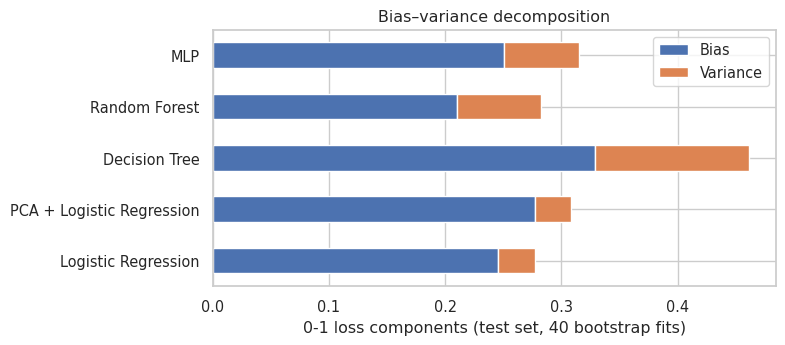

In [ ]:
def bv_decomp(est, thr, B=40):
    rg = np.random.default_rng(RS); preds = []
    est = clone(est)
    if "clf__n_estimators" in est.get_params():
        est.set_params(clf__n_estimators=100)
    for _ in range(B):
        ii = rg.integers(0, len(X_train), len(X_train))
        m = clone(est).fit(X_train.iloc[ii], y_train.iloc[ii])
        preds.append((m.predict_proba(X_test)[:, 1] >= thr).astype(int))
    P = np.array(preds); main = (P.mean(0) >= .5).astype(int)
    return dict(Bias=(main != yt).mean(), Variance=(P != main).mean(), Expected_error=(P != yt).mean())

bv = {n: bv_decomp(fitted[n], THR[n]) for n in five}   # each model evaluated at its own screening threshold
bv_df = pd.DataFrame(bv).T
display(bv_df.round(3)); save_table(bv_df.round(4), "bias_variance_decomposition")
ax = bv_df[["Bias", "Variance"]].plot(kind="barh", stacked=True, figsize=(8, 3.6), color=["#4c72b0", "#dd8452"])
ax.set_xlabel("0-1 loss components (test set, 40 bootstrap fits)"); ax.set_title("Bias–variance decomposition")
savefig("fig12_bias_variance")

**Bias–variance interpretation**
* **Logistic Regression / PCA + LR – high bias, low variance.** Train and validation AUC differ by < 0.01, the learning curves are flat, and bootstrap variance is the lowest (0.032). They cannot over-fit, but they also cannot capture non-linear structure; more data would not help much.
* **Decision Tree – high variance.** Training AUC 0.90 vs validation 0.79 (gap 0.11), and the highest prediction variance across bootstrap fits (0.133). The validation curve shows the classic pattern: training AUC keeps rising with depth while validation AUC peaks early and then falls.
* **Random Forest – variance reduced by bagging.** Averaging many trees cuts prediction variance from 0.133 (single tree) to 0.072 and lifts validation AUC from 0.78 to 0.845. Its large train–validation gap (0.98 vs 0.845) is partly an artefact of scoring a forest on rows it was trained on, so validation AUC is the number that counts.
* **MLP – in between** (gap 0.05, variance 0.065); strong L2 regularisation (`alpha = 1`) is what keeps it from over-fitting the duplicated minority rows.
* **Caveat:** the decomposition is evaluated at each model's own 80%-recall operating point, so absolute "bias" values mostly reflect the false-positive rate at that point; the *variance* column is the reliable comparison.

**Take-away:** with ~200 events the limiting factor is **bias/irreducible noise in the data, not model capacity** – which is why all reasonably regularised models converge to about the same AUC.

## 9. Does imbalance handling matter?  And are 4 features enough?
### 9a. Imbalance strategy ablation (5-fold CV, training data)

In [ ]:
def plain_steps(name, cols=ALL, keep_sampler=False):
    steps = []
    for n_, s_ in fitted[name].steps:
        if n_ == "prep":
            steps.append((n_, make_prep([c for c in num_cols if c in cols], [c for c in bin_cols if c in cols], [c for c in cat_cols if c in cols])))
        elif n_ in ("ros", "sampler") and not keep_sampler:
            continue
        else:
            steps.append((n_, clone(s_)))
    return steps

abl_rows = []
for name in ["Logistic Regression", "Random Forest"]:
    base_steps = plain_steps(name)
    variants = {}
    st = [(a, (clone(b).set_params(class_weight=None) if a == "clf" else b)) for a, b in base_steps]
    variants["No handling"] = Pipeline(st)
    variants["Class weights"] = Pipeline(base_steps)
    st2 = base_steps[:-1] + [("smote", SMOTE(random_state=RS)), ("clf", clone(base_steps[-1][1]).set_params(class_weight=None))]
    variants["SMOTE"] = ImbPipeline(st2)
    for vn, vm in variants.items():
        r = cross_validate(vm, X_train, y_train, cv=cv, scoring={"auc": "roc_auc", "ap": "average_precision", "rec": "recall", "prec": "precision"})
        abl_rows.append([name, vn, r["test_auc"].mean(), r["test_ap"].mean(), r["test_rec"].mean(), r["test_prec"].mean()])
abl = pd.DataFrame(abl_rows, columns=["Model", "Strategy", "ROC-AUC", "PR-AUC", "Recall@0.5", "Precision@0.5"]).set_index(["Model", "Strategy"])
display(abl.round(3)); save_table(abl.round(4), "imbalance_ablation")

ROC-AUC  PR-AUC  Recall@0.5  Precision@0.5
Model               Strategy                                                 
Logistic Regression No handling      0.850   0.225       0.000          0.000
                    Class weights    0.854   0.228       0.799          0.137
                    SMOTE            0.852   0.233       0.784          0.138
Random Forest       No handling      0.849   0.249       0.000          0.000
                    Class weights    0.846   0.226       0.438          0.204
                    SMOTE            0.821   0.171       0.236          0.183

### 9b. Re-testing the paper's claim that *age, heart disease, glucose and hypertension* are enough
We rank each feature by its own cross-validated ROC-AUC, then add features one at a time (the paper's "forward addition" idea) – but with leakage-free CV.

,single-feature CV ROC-AUC
age,0.834
bmi,0.644
ever_married,0.618
work_type,0.599
avg_glucose_level,0.598
smoking_status,0.593
hypertension,0.593
heart_disease,0.565
Residence_type,0.521
gender,0.513


,added,LR ROC-AUC,RF ROC-AUC
n_features,,,
1,age,0.834,0.814
2,bmi,0.846,0.823
3,ever_married,0.846,0.827
4,work_type,0.845,0.825
5,avg_glucose_level,0.852,0.838
6,smoking_status,0.851,0.841
7,hypertension,0.855,0.847
8,heart_disease,0.855,0.847
9,Residence_type,0.854,0.844


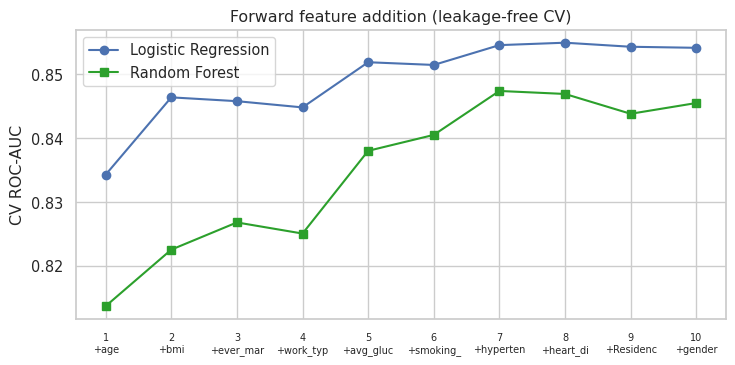

CV ROC-AUC  CV PR-AUC
Model               Feature set                             
Logistic Regression All 10 attributes       0.854      0.228
                    Paper's top-4           0.843      0.188
                    Age only                0.834      0.166
Random Forest       All 10 attributes       0.846      0.226
                    Paper's top-4           0.822      0.167
                    Age only                0.814      0.149

In [ ]:
def cv_auc(name, cols, metric="roc_auc"):
    return cross_val_score_(Pipeline(plain_steps(name, cols)), cols)

def cross_val_score_(model, cols, metric="roc_auc"):
    from sklearn.model_selection import cross_val_score
    return cross_val_score(model, X_train[cols], y_train, cv=cv, scoring=metric).mean()

uni = {c: cv_auc("Logistic Regression", [c]) for c in ALL}
uni_s = pd.Series(uni).sort_values(ascending=False)
display(uni_s.round(3).to_frame("single-feature CV ROC-AUC")); save_table(uni_s.round(4).to_frame("auc"), "univariate_auc")
order = list(uni_s.index)
fw = []
for k in range(1, len(order) + 1):
    cols = order[:k]
    fw.append([k, order[k - 1], cv_auc("Logistic Regression", cols), cv_auc("Random Forest", cols)])
fw_df = pd.DataFrame(fw, columns=["n_features", "added", "LR ROC-AUC", "RF ROC-AUC"]).set_index("n_features")
display(fw_df.round(3)); save_table(fw_df.round(4), "forward_addition")
plt.figure(figsize=(7.5, 3.8))
plt.plot(fw_df.index, fw_df["LR ROC-AUC"], "o-", label="Logistic Regression"); plt.plot(fw_df.index, fw_df["RF ROC-AUC"], "s-", c="#2ca02c", label="Random Forest")
plt.xticks(fw_df.index, [f"{i}\n+{a[:8]}" for i, a in zip(fw_df.index, fw_df["added"])], fontsize=7)
plt.ylabel("CV ROC-AUC"); plt.title("Forward feature addition (leakage-free CV)"); plt.legend()
savefig("fig13_forward_addition")
ab_rows = []
for name in ["Logistic Regression", "Random Forest"]:
    for lab, cols in {"All 10 attributes": ALL, "Paper's top-4": TOP4, "Age only": ["age"]}.items():
        ab_rows.append([name, lab, cv_auc(name, cols), cross_val_score_(Pipeline(plain_steps(name, cols)), cols, "average_precision")])
ab_df = pd.DataFrame(ab_rows, columns=["Model", "Feature set", "CV ROC-AUC", "CV PR-AUC"]).set_index(["Model", "Feature set"])
display(ab_df.round(3)); save_table(ab_df.round(4), "feature_set_ablation")

**What the ablations show**
* **Imbalance handling changes the threshold behaviour, not the ranking.** Without class weights the models have the same ROC-AUC (0.85) but recall 0 at the 0.5 cut-off, because probabilities are all below 0.5 – the problem is fixed by moving the threshold (Section 6) or by class weights. **SMOTE gave no gain for Logistic Regression and clearly hurt Random Forest** (PR-AUC 0.171 vs 0.226), which is why class weights were used.
* **The paper's "4 features are enough" claim is only partly supported on this data.** With leakage-free CV, the paper's top-4 (age, heart disease, glucose, hypertension) loses about 0.01 ROC-AUC and 0.04 PR-AUC for Logistic Regression, and 0.02 / 0.06 for Random Forest, compared with all 10 attributes. Ranking features by their own CV AUC puts age far ahead (0.83), then BMI, marital status, work type and glucose. Adding the remaining variables lifts Logistic Regression from 0.834 (age alone) to 0.855 – a modest gain, driven mostly by BMI, glucose and hypertension. Heart disease, residence and gender add essentially nothing once age is known.

### 9c. Sensitivity: how much does the *"BMI not recorded"* flag matter?
Patients with a missing BMI have a stroke rate of ~20% (vs ~5% overall). That may be a **data-collection artefact** (e.g. BMI not measured for very ill patients) rather than a biological effect, so we check how much the models depend on it.

In [ ]:
sens_rows = []
for name in ["Logistic Regression", "Random Forest"]:
    for lab, ind in {"with BMI-missing flag": True, "without flag (median impute only)": False}.items():
        st = [(a, make_prep(ind=ind) if a == "prep" else b) for a, b in plain_steps(name)]
        r = cross_validate(Pipeline(st), X_train, y_train, cv=cv, scoring={"auc": "roc_auc", "ap": "average_precision"})
        sens_rows.append([name, lab, r["test_auc"].mean(), r["test_ap"].mean()])
sens = pd.DataFrame(sens_rows, columns=["Model", "Variant", "CV ROC-AUC", "CV PR-AUC"]).set_index(["Model", "Variant"])
display(sens.round(3)); save_table(sens.round(4), "bmi_flag_sensitivity")
lr_with, lr_wo = sens.loc[("Logistic Regression",)].iloc[0], sens.loc[("Logistic Regression",)].iloc[1]
display(Markdown(f"Removing the flag changes Logistic Regression CV ROC-AUC from **{lr_with['CV ROC-AUC']:.3f}** to **{lr_wo['CV ROC-AUC']:.3f}** "
                 f"and PR-AUC from **{lr_with['CV PR-AUC']:.3f}** to **{lr_wo['CV PR-AUC']:.3f}**. "
                 "If the model were to be deployed where BMI is always measured, it should be re-validated without this flag."))

CV ROC-AUC  CV PR-AUC
Model               Variant                                                 
Logistic Regression with BMI-missing flag                   0.854      0.228
                    without flag (median impute only)       0.840      0.187
Random Forest       with BMI-missing flag                   0.846      0.226
                    without flag (median impute only)       0.839      0.193

Removing the flag changes Logistic Regression CV ROC-AUC from **0.854** to **0.840** and PR-AUC from **0.228** to **0.187**. If the model were to be deployed where BMI is always measured, it should be re-validated without this flag.

## 10. Interpretability: what drives stroke risk?
### 10a. Multivariable odds ratios (statsmodels logistic regression, training data)
`work_type` categories *children* and *Never_worked* are merged (the latter has 0 strokes → perfect separation).

,OR,CI low,CI high,p
ever_married vs No = Yes,0.743,0.452,1.221,0.241
gender vs Female = Male,1.035,0.754,1.420,0.832
Residence_type vs Rural = Urban,1.072,0.788,1.459,0.656
work_type vs Private = Child/NeverWorked,1.347,0.156,11.652,0.787
work_type vs Private = Govt_job,0.958,0.611,1.503,0.853
work_type vs Private = Self-employed,0.755,0.524,1.088,0.132
smoking_status vs never smoked = Unknown,1.013,0.649,1.580,0.955
smoking_status vs never smoked = formerly smoked,1.225,0.828,1.811,0.309
smoking_status vs never smoked = smokes,1.278,0.808,2.022,0.295
Age (per +10 years),2.079,1.829,2.363,0.000


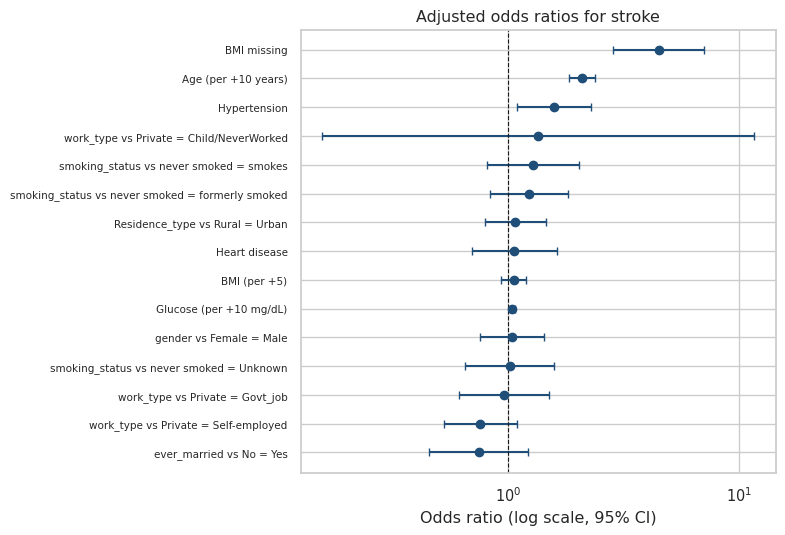

In [ ]:
tr = X_train.copy(); tr["stroke"] = y_train.values
tr["bmi_missing"] = tr.bmi.isna().astype(int); tr["bmi"] = tr.bmi.fillna(tr.bmi.median())
tr["work_type"] = tr.work_type.replace({"children": "Child/NeverWorked", "Never_worked": "Child/NeverWorked"})
f = ("stroke ~ I(age/10) + I(avg_glucose_level/10) + I(bmi/5) + bmi_missing + hypertension + heart_disease + "
     "C(ever_married, Treatment('No')) + C(gender, Treatment('Female')) + C(Residence_type, Treatment('Rural')) + "
     "C(work_type, Treatment('Private')) + C(smoking_status, Treatment('never smoked'))")
sm_fit = smf.logit(f, data=tr).fit(disp=0)
orr = pd.DataFrame({"OR": np.exp(sm_fit.params), "CI low": np.exp(sm_fit.conf_int()[0]), "CI high": np.exp(sm_fit.conf_int()[1]), "p": sm_fit.pvalues}).drop("Intercept")
nice = {"I(age / 10)": "Age (per +10 years)", "I(avg_glucose_level / 10)": "Glucose (per +10 mg/dL)", "I(bmi / 5)": "BMI (per +5)",
        "bmi_missing": "BMI missing", "hypertension": "Hypertension", "heart_disease": "Heart disease"}
orr.index = [nice.get(i, i.replace("C(", "").replace(", Treatment(", " vs ").replace("'", "").replace(")[T.", " = ").replace("]", "").replace(")", "")) for i in orr.index]
display(orr.round(3)); save_table(orr.round(4), "odds_ratios")
o = orr.sort_values("OR")
plt.figure(figsize=(8, 5.5))
plt.errorbar(o.OR, range(len(o)), xerr=[o.OR - o["CI low"], o["CI high"] - o.OR], fmt="o", c="#1f4e79", capsize=3)
plt.axvline(1, c="k", ls="--", lw=.8); plt.xscale("log"); plt.yticks(range(len(o)), o.index, fontsize=7.5)
plt.xlabel("Odds ratio (log scale, 95% CI)"); plt.title("Adjusted odds ratios for stroke")
savefig("fig14_odds_ratios")

### 10b. Permutation importance (test set) – model-agnostic, drop in ROC-AUC when a feature is shuffled

,Logistic Regression,PCA + Logistic Regression,Decision Tree,Random Forest,MLP
age,0.2795,0.2634,0.2744,0.2618,0.3145
bmi,0.0047,0.0055,0.0373,0.0105,0.0173
avg_glucose_level,0.0042,0.0032,0.0251,0.0180,0.0166
smoking_status,0.0009,0.0008,0.0058,0.0066,0.0041
work_type,0.0003,0.0010,0.0000,0.0038,0.0040
heart_disease,0.0013,0.0008,-0.0001,0.0033,0.0018
ever_married,-0.0002,0.0013,0.0000,-0.0010,0.0021
gender,-0.0006,0.0000,0.0000,-0.0003,-0.0005
hypertension,-0.0002,-0.0003,0.0000,-0.0005,-0.0020
Residence_type,-0.0007,0.0001,0.0000,-0.0032,-0.0006


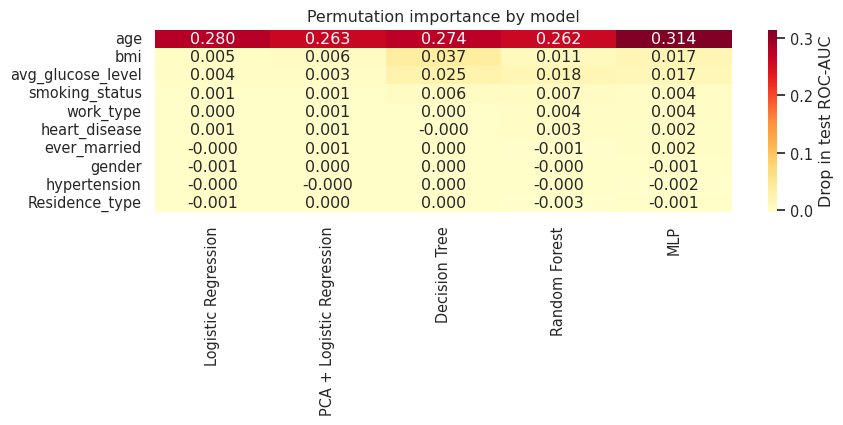

In [ ]:
pi = {}
for n in five:
    r = permutation_importance(fitted[n], X_test, y_test, scoring="roc_auc", n_repeats=20, random_state=RS, n_jobs=1)
    pi[n] = pd.Series(r.importances_mean, index=X_test.columns)
pi_df = pd.DataFrame(pi); pi_df = pi_df.loc[pi_df.mean(1).sort_values(ascending=False).index]
display(pi_df.round(4)); save_table(pi_df.round(5), "permutation_importance")
plt.figure(figsize=(9, 4.4))
sns.heatmap(pi_df, annot=True, fmt=".3f", cmap="YlOrRd", cbar_kws={"label": "Drop in test ROC-AUC"})
plt.title("Permutation importance by model"); savefig("fig15_permutation_importance")

**Interpretation of 10a and 10b**
* **Age is the dominant driver** in every model: odds ratio **2.08 per +10 years** (95% CI 1.83–2.36), and shuffling age drops test ROC-AUC by 0.26–0.31, versus ≤ 0.04 for any other feature.
* After adjusting for age, **hypertension (OR 1.58, 1.09–2.27)** and **glucose (OR 1.04 per +10 mg/dL, 1.01–1.07)** remain significant risk factors.
* **`ever_married`, `work_type`, `gender`, `Residence_type` and `smoking_status` are not significant once age is in the model**, confirming that marital status and work type were only **proxies for age**. This is a correction to the reference paper, which highlighted marital status as a strong contributor on the first principal component.
* **Heart disease** has a strong *crude* association (Cramér's V = 0.13) but an adjusted OR of only 1.06 (ns) – largely explained by age in this sample. Non-significance with ~200 events is *absence of evidence*, not evidence of absence.
* **"BMI missing" has OR 4.5 (2.9–7.1)** – a large effect that is probably a recording artefact (Section 9c) and should not be read as a clinical risk factor.

### 10c. Partial dependence and decision-tree rules

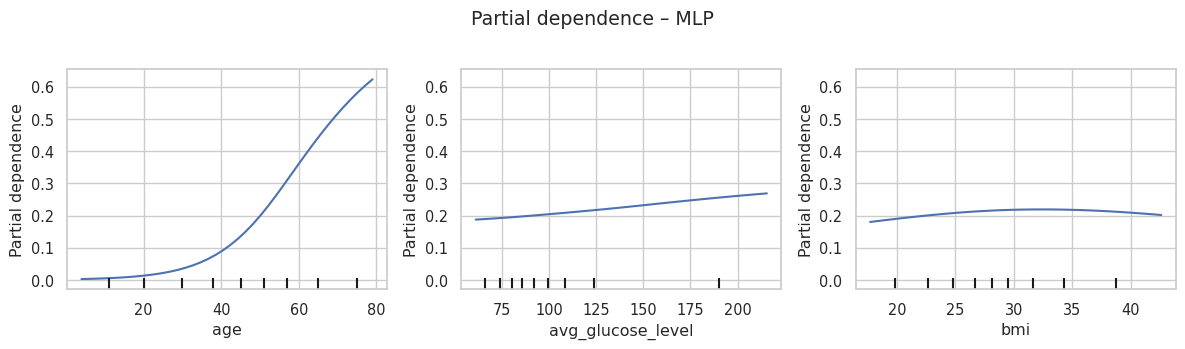

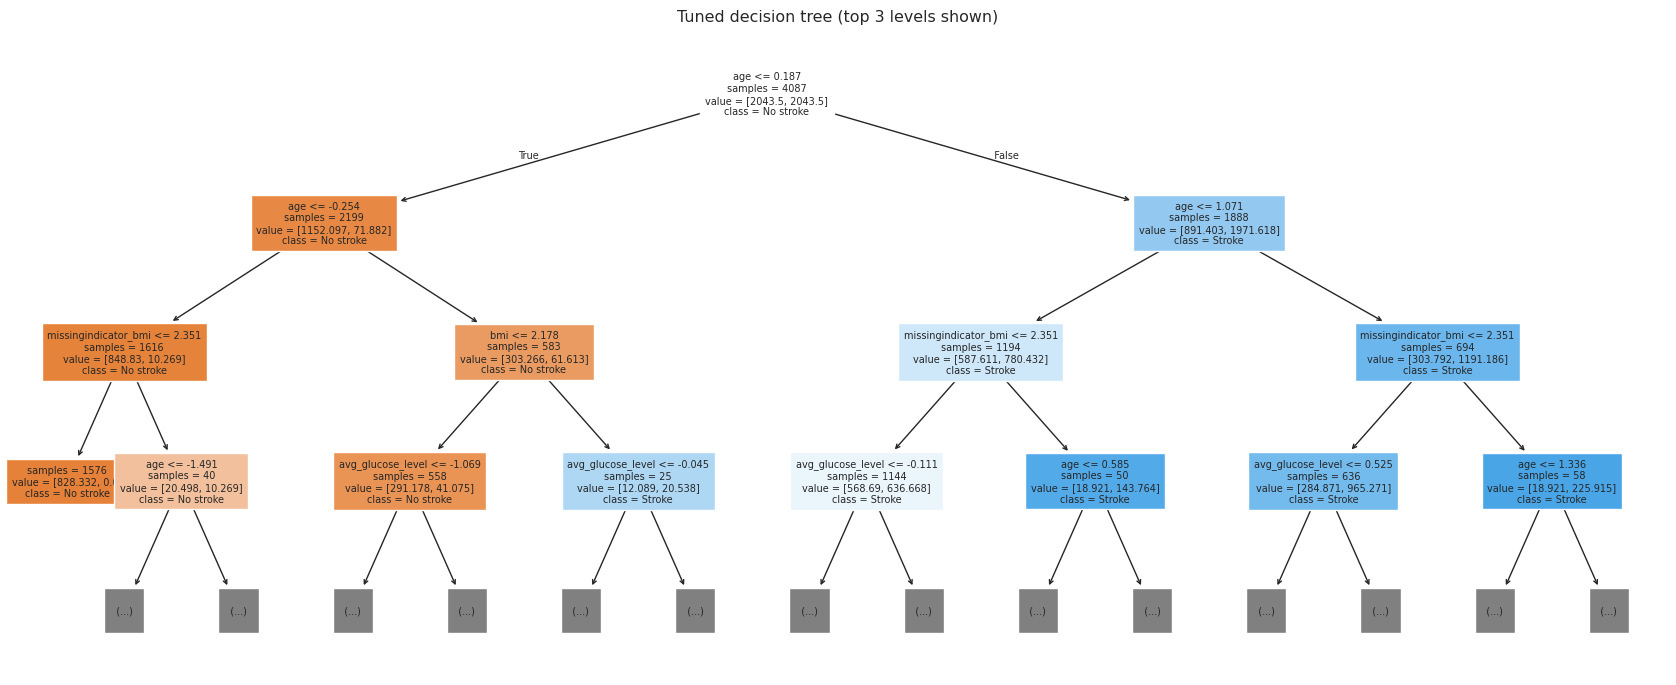

|--- age <= 0.19
|   |--- age <= -0.25
|   |   |--- missingindicator_bmi <= 2.35
|   |   |   |--- class: 0
|   |   |--- missingindicator_bmi >  2.35
|   |   |   |--- age <= -1.49
|   |   |   |   |--- class: 1
|   |   |   |--- age >  -1.49
|   |   |   |   |--- class: 0
|   |--- age >  -0.25
|   |   |--- bmi <= 2.18
|   |   |   |--- avg_glucose_level <= -1.07
|   |   |   |   |--- class: 1
|   |   |   |--- avg_glucose_level >  -1.07
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- bmi >  2.18
|   |   |   |--- avg_glucose_level <= -0.04
|   |   |   |   |--- class: 0
|   |   |   |--- avg_glucose_level >  -0.04
|   |   |   |   |--- class: 1
|--- age >  0.19
|   |--- age <= 1.07
|   |   |--- missingindicator_bmi <= 2.35
|   |   |   |--- avg_glucose_level <= -0.11
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- avg_glucose_level >  -0.11
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- missingindicator_bmi >  2.35
|   |   |   |--- age <= 0.58
|   |  

In [ ]:
Xp = X_train.copy(); Xp["bmi"] = Xp.bmi.fillna(Xp.bmi.median())
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
PartialDependenceDisplay.from_estimator(final_model, Xp, ["age", "avg_glucose_level", "bmi"], ax=ax, kind="average", grid_resolution=40)
fig.suptitle(f"Partial dependence – {final_name}", y=1.02); savefig("fig16_partial_dependence")

dt_best = fitted["Decision Tree"]; dt_names = list(dt_best.named_steps["prep"].get_feature_names_out())
plt.figure(figsize=(17, 7))
plot_tree(dt_best.named_steps["clf"], feature_names=dt_names, class_names=["No stroke", "Stroke"], filled=True, max_depth=3,
          fontsize=7, proportion=False, impurity=False)
plt.title("Tuned decision tree (top 3 levels shown)"); savefig("fig17_decision_tree")
print(export_text(dt_best.named_steps["clf"], feature_names=dt_names, max_depth=3))

## 11. Probability calibration and clinical usefulness  *(CO6)*

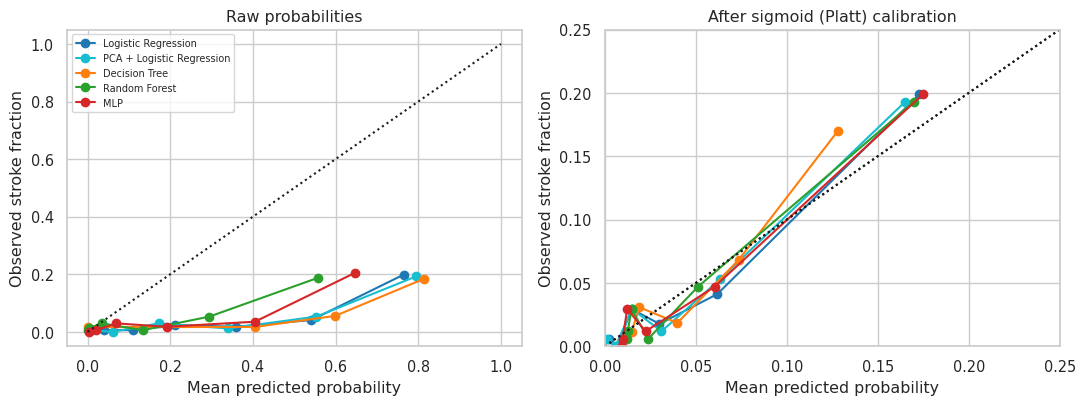

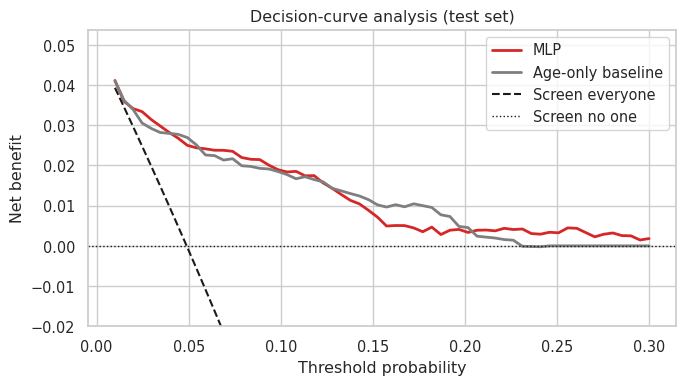

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for n in five:
    for a, P_, ttl in [(ax[0], P_test[n], "Raw probabilities"), (ax[1], P_cal[n], "After sigmoid (Platt) calibration")]:
        fo, mp = calibration_curve(yt, P_, n_bins=6, strategy="quantile")
        a.plot(mp, fo, "o-", c=MC[n], label=n); a.set_title(ttl)
for a in ax:
    a.plot([0, 1], [0, 1], "k:"); a.set_xlabel("Mean predicted probability"); a.set_ylabel("Observed stroke fraction")
ax[1].set_xlim(0, .25); ax[1].set_ylim(0, .25); ax[1].plot([0, .25], [0, .25], "k:"); ax[0].legend(fontsize=7)
savefig("fig18_calibration")

# Decision-curve analysis (net benefit)
pts = np.linspace(0.01, 0.30, 60); prev = yt.mean(); nb = {}
for n in [final_name, "Age-only baseline"]:
    p_ = P_cal[n]
    nb[n] = [((p_ >= t) & (yt == 1)).sum() / len(yt) - ((p_ >= t) & (yt == 0)).sum() / len(yt) * t / (1 - t) for t in pts]
treat_all = [prev - (1 - prev) * t / (1 - t) for t in pts]
plt.figure(figsize=(7, 4))
for n in nb:
    plt.plot(pts, nb[n], c=MC[n], lw=2, label=n)
plt.plot(pts, treat_all, c="k", ls="--", label="Screen everyone"); plt.axhline(0, c="k", lw=1, ls=":", label="Screen no one")
plt.ylim(-0.02, prev * 1.1); plt.xlabel("Threshold probability"); plt.ylabel("Net benefit"); plt.legend(); plt.title("Decision-curve analysis (test set)")
savefig("fig19_decision_curve")

**Calibration and net benefit.** Raw probabilities from the class-weighted models sit far below the diagonal (they were trained as if strokes were common); after sigmoid calibration all five models track the diagonal closely up to ≈ 20% predicted risk. In the decision-curve analysis, both the MLP and the age-only model give positive net benefit over "screen everyone" for any threshold above ≈ 2% and over "screen no one" up to ≈ 20–30%. The two curves are almost indistinguishable – the MLP is slightly higher below ≈ 12% and above ≈ 20%, age-only slightly higher in between – so **the practical clinical gain of the multivariable model over simple age-based screening is small on this data**.

## 12. Like-for-like comparison with the reference paper's protocol
The paper (i) kept **all stroke cases and an equal number of random non-stroke cases** (balanced 1:1), (ii) split 70:30, (iii) averaged over repeated random sub-samplings, (iv) reported accuracy etc. **on the balanced test split**. We replicate exactly that protocol with our tuned models (50 repetitions) so the numbers are comparable in *protocol*.
**Important caveat:** the paper used a 29,072-record version of the data (548 strokes); the Kaggle file used here has 5,110 records (249 strokes). The two are therefore not identical datasets, so this is a protocol-matched comparison, not a head-to-head on identical data.

In [ ]:
PAPER = {  # Table 2 of Dev et al. (2022): Accuracy / Precision / Recall / F-score
    ("All 10 attributes", "Decision Tree"): (0.74, 0.75, 0.74, 0.74), ("All 10 attributes", "Random Forest"): (0.74, 0.74, 0.73, 0.73),
    ("All 10 attributes", "MLP"): (0.77, 0.80, 0.74, 0.77),
    ("Paper's top-4", "Decision Tree"): (0.75, 0.78, 0.71, 0.74), ("Paper's top-4", "Random Forest"): (0.75, 0.76, 0.74, 0.75),
    ("Paper's top-4", "MLP"): (0.75, 0.78, 0.71, 0.74)}
pos_df = df[df.stroke == 1]; neg_df = df[df.stroke == 0]
N_REP = 50; prot = []
for r in range(N_REP):
    bal = pd.concat([pos_df, neg_df.sample(len(pos_df), random_state=r)]).sample(frac=1, random_state=r)
    Xb, yb = bal.drop(columns="stroke"), bal.stroke
    Xa, Xc, ya, yc = train_test_split(Xb, yb, test_size=0.3, stratify=yb, random_state=r)
    for fs, cols in {"All 10 attributes": ALL, "Paper's top-4": TOP4}.items():
        for name in ["Logistic Regression", "Decision Tree", "Random Forest", "MLP"]:
            m = Pipeline(plain_steps(name, cols)).fit(Xa[cols], ya)
            p_ = m.predict_proba(Xc[cols])[:, 1]; mt = metrics_at(yc.values, p_, 0.5)
            prot.append(dict(Features=fs, Model=name, Accuracy=mt["Accuracy"], Precision=mt["Precision"], Recall=mt["Recall"], F1=mt["F1"],
                             Miss_rate=1 - mt["Recall"], AUC=roc_auc_score(yc, p_)))
prot_df = pd.DataFrame(prot).groupby(["Features", "Model"]).agg(["mean", "std"])
mean_tab = pd.DataFrame(prot).groupby(["Features", "Model"]).mean()
mean_tab["Paper accuracy"] = [PAPER.get(k, (np.nan,))[0] for k in mean_tab.index]
mean_tab["Paper F1"] = [PAPER.get(k, (np.nan,) * 4)[3] for k in mean_tab.index]
display(mean_tab.round(3)); save_table(mean_tab.round(4), "paper_protocol_comparison")
FACTS["paper_protocol_n_rep"] = N_REP

Accuracy  Precision  Recall     F1  \
Features          Model                                                     
All 10 attributes Decision Tree           0.726      0.706   0.782  0.740   
                  Logistic Regression     0.771      0.746   0.825  0.783   
                  MLP                     0.768      0.747   0.814  0.778   
                  Random Forest           0.769      0.736   0.843  0.785   
Paper's top-4     Decision Tree           0.729      0.712   0.776  0.741   
                  Logistic Regression     0.770      0.743   0.827  0.782   
                  MLP                     0.769      0.744   0.825  0.781   
                  Random Forest           0.760      0.732   0.826  0.775   

                                       Miss_rate    AUC  Paper accuracy  \
Features          Model                                                   
All 10 attributes Decision Tree            0.218  0.790            0.74   
                  Logistic Regression      0.175  0.845             NaN   
                  MLP                      0.186  0.842            0.77   
                  Random Forest            0.157  0.838            0.74   
Paper's top-4     Decision Tree            0.224  0.788            0.75   
                  Logistic Regression      0.173  0.839             NaN   
                  MLP                      0.175  0.840            0.75   
                  Random Forest            0.174  0.828            0.75   

                                       Paper F1  
Features          Model                          
All 10 attributes Decision Tree            0.74  
                  Logistic Regression       NaN  
                  MLP                      0.77  
                  Random Forest            0.73  
Paper's top-4     Decision Tree            0.74  
                  Logistic Regression       NaN  
                  MLP                      0.74  
                  Random Forest            0.75

## 13. Honest operating-point summary and a worked example

In [ ]:
summary = pd.DataFrame({
    "ROC-AUC": tab_rank["ROC_AUC"], "PR-AUC": tab_rank["PR_AUC"], "LogLoss (calibrated)": tab_rank["LogLoss_calibrated"],
    "Recall @screen": tab_scr["Recall"], "Precision @screen": tab_scr["Precision"], "Specificity @screen": tab_scr["Specificity"],
    "% population flagged": tab_scr["Flagged_pct"], "Lift vs random": tab_scr["Lift"], "F2 @screen": tab_scr["F2"]})
display(summary.round(3)); save_table(summary.round(4), "final_summary")

,ROC-AUC,PR-AUC,LogLoss (calibrated),Recall @screen,Precision @screen,Specificity @screen,% population flagged,Lift vs random,F2 @screen
Logistic Regression,0.835,0.209,0.159,0.82,0.141,0.744,28.376,2.890,0.418
PCA + Logistic Regression,0.836,0.204,0.159,0.82,0.130,0.717,30.920,2.652,0.397
Decision Tree,0.785,0.170,0.168,0.82,0.090,0.572,44.716,1.834,0.312
Random Forest,0.820,0.238,0.159,0.74,0.129,0.743,28.082,2.635,0.380
MLP,0.840,0.231,0.156,0.82,0.133,0.724,30.235,2.712,0.403
Age-only baseline,0.835,0.209,0.157,0.82,0.134,0.728,29.843,2.748,0.406


**Operating-point summary.** With the screening threshold, four of the five models (and the age baseline) catch about 8 in 10 strokes at the price of flagging roughly 3 in 10 people, i.e. ≈ 2.7–2.9× better than random targeting. The Decision Tree is dominated on every metric.

In [ ]:
joblib.dump(final_model, "final_model.joblib")
demo = pd.DataFrame([
    dict(gender="Female", age=34, hypertension=0, heart_disease=0, ever_married="Yes", work_type="Private", Residence_type="Urban", avg_glucose_level=88.0, bmi=24.5, smoking_status="never smoked"),
    dict(gender="Male", age=58, hypertension=1, heart_disease=0, ever_married="Yes", work_type="Self-employed", Residence_type="Rural", avg_glucose_level=135.0, bmi=31.0, smoking_status="formerly smoked"),
    dict(gender="Male", age=76, hypertension=1, heart_disease=1, ever_married="Yes", work_type="Private", Residence_type="Urban", avg_glucose_level=218.0, bmi=29.0, smoking_status="smokes")],
    index=["Patient A", "Patient B", "Patient C"])
dem = demo.copy()
dem["risk_score"] = final_model.predict_proba(demo)[:, 1]
dem["calibrated_risk_%"] = CalibratedClassifierCV(clone(final_model), method="sigmoid", cv=5).fit(X_train, y_train).predict_proba(demo)[:, 1] * 100
dem["flag_for_screening"] = dem.risk_score >= THR[final_name]
display(dem[["age", "hypertension", "heart_disease", "avg_glucose_level", "risk_score", "calibrated_risk_%", "flag_for_screening"]].round(3))
save_table(dem.round(4), "demo_patients")

with open("results/facts.json", "w") as fh:
    json.dump({**FACTS, "thresholds": {k: float(v) for k, v in THR.items()}}, fh, indent=2, default=float)
print("Saved model, figures and result tables.")

,age,hypertension,heart_disease,avg_glucose_level,risk_score,calibrated_risk_%,flag_for_screening
Patient A,34,0,0,88.0,0.027,1.001,False
Patient B,58,1,0,135.0,0.539,8.791,True
Patient C,76,1,1,218.0,0.801,33.592,True


Saved model, figures and result tables.


## 14. Conclusions, limitations and future scope

### Conclusions
1. **End-to-end solution delivered** for a real-world screening problem: leakage-free pipelines, five tuned models (Logistic Regression, PCA + LR, Decision Tree, Random Forest, MLP), PCA and K-Means analysis, and evaluation with every syllabus metric (Accuracy, Precision, Recall, F1, Log-Loss, AUC, Confusion Matrix) plus PR-AUC, calibration and decision-curve analysis.
2. **Best-performing models** reach **ROC-AUC ≈ 0.84** and, at an 80%-sensitivity screening threshold, flag ≈ 30% of patients with ≈ 14% precision (≈ 2.8× lift). The four better models are statistically tied; Logistic Regression is the most interpretable and the most stable (lowest variance), the MLP has the highest CV PR-AUC and was selected by the pre-declared rule, and the Decision Tree is consistently the weakest.
3. **Age explains most of the predictable signal.** An age-only model reaches ROC-AUC 0.835. Extra variables (BMI, glucose, hypertension) give a modest but measurable gain, mostly in PR-AUC (0.17 → 0.23–0.25).
4. **Corrections to the reference paper:** (a) the 4-feature subset is *not* sufficient once evaluated without leakage; (b) marital status / work type are age proxies; (c) balanced-test-set accuracy overstates real-world performance – under the paper's own protocol our models score about 0.77 accuracy / 0.82–0.84 recall (comparable to or slightly above the paper's 0.74–0.77), but under a realistic protocol precision is only ≈ 14%.
5. **Bias–variance:** simple models are high-bias/low-variance, the unregularised tree is high-variance, and bagging (Random Forest) reduces variance substantially. The ceiling is set by the information in ~200 stroke cases, not by model complexity.

### Limitations
* Only 249 stroke cases (50 in the test set) → wide confidence intervals; differences among the top models cannot be resolved.
* The dataset's origin is not documented, `bmi` missingness is strongly (and possibly artefactually) linked to stroke, and the stroke label's timing relative to the other measurements is unknown, so the model supports **screening prioritisation**, not clinical diagnosis. It has not been externally validated.
* Smoking status is unknown for ~30% of patients, and no information on diet, medication, family history or atrial fibrillation is available.
* Protocol-matched comparison with the paper is **not on identical data** (29,072 vs 5,110 records).

### Future scope
* External validation on an independent hospital dataset; temporal validation.
* Add richer predictors (atrial fibrillation, lipid profile, family history, medication) and gradient-boosted models with monotonic constraints.
* Fairness audit across gender/age groups; cost-sensitive threshold selection with clinicians.
* Deploy the calibrated model as a risk calculator with uncertainty intervals.